# Project 1: River Watch: Redwood River near Marshall, MN

### Research Question
How does the Redwood River respond to rainfall, and how often does it pass flood level?

### Selected Data Sources
1. USGS Water Data API – Daily stream discharge.
2. Open-Meteo Historical Weather API – Daily precipitation, snowfall, and temperature.

### Selected Gauge
- Monitoring Location: USGS-05315000
- Latitude: 44.430156
- Longitude: -95.82945

### Pipeline Plan
Extract → Transform → Load → Analyze

The pipeline will retrieve historical river discharge and weather data, clean and combine the datasets, store the results in SQLite and CSV files, and create visualizations to investigate the relationship between rainfall and river discharge.

The cell below imports the libraries required for this project. It will retrieve information from USGS and Open-Meteo, then clean and organize the data via Pandas. Matplotlib will create the charts, while SQLite3 will allow for the storing and querying of the cleaned data sets. JSON and datetime will handle API responses and dates. Setup should be successful.

In [1]:
##Step 1.1: Set Up Google Colab
import requests
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3
import json
import datetime
import os

The libraries have been successfully imported, and can now be used for the project.

The cell below creates two folders for organizing project data, data/raw holds the API responses, and data/clean holds the cleaned datasets. Having the raw and cleaned data be seperate preserves the original information if correcting a cleaning decision is nedded. os.makedirs("data/raw", exist_ok=True) and os.makedirs("data/clean", exist_ok=True) ensures there won't be errors if the directories already exist. "Project folders are ready" should be printed if successful.

In [2]:
##Step 1.2: Create Project Folders
import os

os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/clean", exist_ok=True)

print("Project folders are ready.")

Project folders are ready.


These directories now exist, and will hold the raw and processed data.

The cell below requests daily streamflow measurements from USGS Water Data API, which tells us how much water passes through the river per day in cubic feet per second. I used requests.get(url, params=params, timeout=30") to specify monitoring location, discharge parameter, and date range. I expect a number of records to be returned.

In [3]:
##Step 2.1: Request Daily Streamflow Data
# USGS Daily Values API
url = "https://api.waterdata.usgs.gov/ogcapi/v1/collections/daily/items"

# Parameters for the API request
params = {
    "monitoring_location_id": "USGS-05315000",
    "parameter_code": "00060",
    "statistic_id": "00003",
    "datetime": "2023-11-01/2026-11-01",
    "limit": 10000,
    "f": "json"
}

try:
    response = requests.get(url, params=params, timeout=30)

    response.raise_for_status()

    usgs_data = response.json()

    print("USGS API request successful!")
    print("Records returned:", len(usgs_data["features"]))

except requests.exceptions.RequestException as error:
    print("USGS API request failed:", error)

USGS API request successful!
Records returned: 1095


I have successfully made API requests to USGS Water Data.

The cell below saves the raw data from the USGS API into data/raw/, which allows me to work a local copy of said data. response.text is used to preserve the original response. This helps keep the raw and cleaned data separate, which will be created later. Data should get successfully saved.

In [4]:
##Step 2.2: Save the Raw API Data Response
# Save the original USGS response
raw_file = "data/raw/usgs_discharge_january_2025.json"

with open(raw_file, "w") as file:
    file.write(response.text)

print("Raw USGS data saved successfully.")
print("File:", raw_file)

Raw USGS data saved successfully.
File: data/raw/usgs_discharge_january_2025.json


The original USGS API response has been saved as a JSON file, and can now be access locally.

The cell below examines the structure of data returned by USGS Water Data API.Each daily observation is stored as a feature, whose measurements are contained in a properities section. So I printed top-level JSON keys inside the first feature to understand how its information is organized. This helps me know which fields I need when converting the raw data into a table. Output should show the data structure with keys and properties.

In [5]:
##Step 3.1: Inspect the JSON Structure
# Examine the overall JSON structure
print("Top-level JSON keys:")
print(usgs_data.keys())

# Examine the first observation
first_feature = usgs_data["features"][0]

print("\nFirst feature keys:")
print(first_feature.keys())

print("\nFirst feature properties:")
print(first_feature["properties"])

Top-level JSON keys:
dict_keys(['type', 'features', 'numberReturned', 'links', 'timeStamp'])

First feature keys:
dict_keys(['type', 'properties', 'id', 'geometry'])

First feature properties:
{'time_series_id': 'b16dc152c8c34f12954d0d91d4562600', 'monitoring_location_id': 'USGS-05315000', 'parameter_code': '00060', 'statistic_id': '00003', 'time': '2024-06-19', 'value': '426', 'unit_of_measure': 'ft^3/s', 'approval_status': 'Approved', 'qualifier': None, 'last_modified': '2025-06-05T19:42:11.416342+00:00'}


The top-level JSON keys, first feature keys, and first feature properties are printed out. First feature properties seems to have the relevant data.

The cell below converts GeoJSON observations into a pandas DataFrame. usgs_df = pd.json_normalize() is used on the properties section since that's where the relevant measurement data is stored. I should get a DataFrame that puts each observation in a row along with its values. I should see a DataFrame along the number of rows and columns.

In [6]:
##Step 3.2: Convert the JSON into a DataFrame
# Extract the properties from each GeoJSON feature
features = usgs_data["features"]

usgs_df = pd.json_normalize(
    [feature["properties"] for feature in features]
)

# Display the first five rows
display(usgs_df.head())

# Show the number of rows and columns
print("Rows:", usgs_df.shape[0])
print("Columns:", usgs_df.shape[1])

,time_series_id,monitoring_location_id,parameter_code,statistic_id,time,value,unit_of_measure,approval_status,qualifier,last_modified
0,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2024-06-19,426,ft^3/s,Approved,None,2025-06-05T19:42:11.416342+00:00
1,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2026-07-13,30.5,ft^3/s,Provisional,None,2026-07-17T16:49:11.613905+00:00
2,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2026-03-14,14.9,ft^3/s,Provisional,[ESTIMATED],2026-07-02T15:30:12.875781+00:00
3,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2026-01-13,8.47,ft^3/s,Provisional,[ESTIMATED],2026-07-02T15:33:13.795133+00:00
4,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2025-01-03,0.80,ft^3/s,Approved,[ESTIMATED],2026-03-24T16:48:20.149463+00:00


Rows: 1095
Columns: 10


The USGS data is organized into 1095 rows and 10 columns, 2 missing days since there 1097 days from the start and end date.

The cell below is a quality check for the DataFrame before it's cleaned. Each colmumn's data type is printed out, with missing values being counted via usgs_df.isna().sum(). These checks are here to identify any potential problems before proceeding with the rest of the project. I should see the data types and missing values.

In [7]:
##Step 3.3: Check the Data Types, Date Range, and Missing Values
# Display the data types
print("Data types:")
print(usgs_df.dtypes)

# Count missing values in each column
print("\nMissing values:")
print(usgs_df.isna().sum())

# Identify the date column
date_columns = [
    column for column in usgs_df.columns
    if column.lower() in ["time", "datetime", "date"]
]

if date_columns:
    date_column = date_columns[0]
    dates = pd.to_datetime(usgs_df[date_column], errors="coerce")

    print("\nDate range:")
    print("Start:", dates.min())
    print("End:", dates.max())
else:
    print("\nNo recognizable date column was found.")
    print("Available columns:", usgs_df.columns.tolist())

Data types:
time_series_id            object
monitoring_location_id    object
parameter_code            object
statistic_id              object
time                      object
value                     object
unit_of_measure           object
approval_status           object
qualifier                 object
last_modified             object
dtype: object

Missing values:
time_series_id              0
monitoring_location_id      0
parameter_code              0
statistic_id                0
time                        0
value                       0
unit_of_measure             0
approval_status             0
qualifier                 764
last_modified               0
dtype: int64

Date range:
Start: 2023-11-01 00:00:00
End: 2026-11-01 00:00:00


There are 0 missing values detected.

The cell below checks for data quality problems, such as duplicate dates, incorrect data types, marked qualifiers, and outliers. Issues and inconsistencies in the data can introduce greater issues if not addressed here. I will use the output of this cell to see which issues need to addressed first. I should see if there are any duplicate dates, what the approval statuses are, and what qualifiers are present.

In [8]:
##Step 3.4: Identify Data Quality Problems
# Check for duplicate dates
if date_columns:
    print(
        "Duplicate dates:",
        dates.duplicated().sum()
    )

# Look for columns that may contain qualifiers
qualifier_columns = [
    column for column in usgs_df.columns
    if "qualifier" in column.lower()
    or "approval" in column.lower()
    or "remark" in column.lower()
]

print("\nPossible qualifier columns:")
print(qualifier_columns)

for column in qualifier_columns:
    print(f"\nValues in {column}:")
    print(usgs_df[column].value_counts(dropna=False).head(10))

Duplicate dates: 0

Possible qualifier columns:
['approval_status', 'qualifier']

Values in approval_status:
approval_status
Approved       749
Provisional    346
Name: count, dtype: int64

Values in qualifier:
qualifier
None                    764
[ESTIMATED]             325
[FORCEINTERPOLATION]      6
Name: count, dtype: int64


There are no duplicate dates. Approval status is 749 approved, and 346 provisional. Qualifiers are 764 none, 325 estimated, and 6 forceinterpolation.

The cell below checks every calendar date within the requested range from November 1st 2023 to November 1st 2026. It compares the number of days within via pd.date_range() against the amount of records from USGS. This is to ensure that no dates are missing from the data set. This also checks for missing unconvertible discharge values. I should see the missing dates and missing discharge values.

In [9]:
##Step 3.5: Check for Missing Dates and Discharge Values
# Convert dates and discharge values to appropriate types
usgs_df["time"] = pd.to_datetime(usgs_df["time"], errors="coerce")
usgs_df["value"] = pd.to_numeric(usgs_df["value"], errors="coerce")

# Generate all expected dates
expected_dates = pd.date_range(
    start="2023-11-01",
    end="2026-11-01",
    freq="D"
)

# Find dates without an observation
missing_dates = expected_dates.difference(
    usgs_df["time"].dropna()
)

print("Expected calendar days:", len(expected_dates))
print("Actual observations:", len(usgs_df))
print("Missing dates:", len(missing_dates))
print("\nMissing date list:")
print(missing_dates.tolist())

# Check discharge values
print("\nMissing discharge values:", usgs_df["value"].isna().sum())
print("Discharge data type:", usgs_df["value"].dtype)

Expected calendar days: 1097
Actual observations: 1095
Missing dates: 2

Missing date list:
[Timestamp('2026-08-10 00:00:00'), Timestamp('2026-08-17 00:00:00')]

Missing discharge values: 0
Discharge data type: float64


There are two missing dates from the data set of 1095 days, since there are actually 1097 calendar days with that 3 year range. There also 0 missing discharge values.

The cell below recreates the DataFrame from the original USGS JSON so the raw data remains unchanged. The time column is converted into datetime format and the volmn column into numeric values. erros+"coerce" is used to prevent unconvertible values becoming missing values instead of causing the cell to fail. The values should be converted, with missing values shown.

In [10]:
##Step 4.1 Recreate the DataFrame and Correct Data Types
# Re-create the DataFrame from the original API response
usgs_clean = pd.json_normalize(
    [feature["properties"] for feature in usgs_data["features"]]
)

rows_before = len(usgs_clean)

# Convert date and discharge columns
usgs_clean["time"] = pd.to_datetime(
    usgs_clean["time"], errors="coerce"
)

usgs_clean["value"] = pd.to_numeric(
    usgs_clean["value"], errors="coerce"
)

print("Rows before conversion:", rows_before)
print("\nUpdated data types:")
print(usgs_clean[["time", "value"]].dtypes)

Rows before conversion: 1095

Updated data types:
time     datetime64[ns]
value           float64
dtype: object


Time is datetime64 and value is now float64. No missing values are present.

The cell below checks for duplicate data, since this project only uses one daily mean discharge measurement. duplicated() is used to count duplicate dates, and drop_duplicates() keeps the first observation if duplicates exists. This should prevent repeated dates from affecting calculations. I should see the amount of rows before and after, along with duplicate dates.

In [11]:
##Step 4.2: Check and Remove Duplicate Dates
rows_before = len(usgs_clean)

duplicate_count = usgs_clean.duplicated(
    subset=["time"]
).sum()

usgs_clean = usgs_clean.drop_duplicates(
    subset=["time"], keep="first"
)

print("Duplicate dates found:", duplicate_count)
print("Rows before:", rows_before)
print("Rows after:", len(usgs_clean))

Duplicate dates found: 0
Rows before: 1095
Rows after: 1095


The number of rows before and after remained at 1095, with no duplicate dates found.

The cell belows checks for observations with invalid dates and missing measurements. Missing dicharge values are unusable, so rows with missing time and discharge values are removed. Missing dates will remain as gaps. The invalid dates, missing discharge values, and rows removed should be printed.

In [12]:
##Step 4.3: Handle Missing and Invalid Measurements
rows_before = len(usgs_clean)

missing_dates = usgs_clean["time"].isna().sum()
missing_values = usgs_clean["value"].isna().sum()

usgs_clean = usgs_clean.dropna(
    subset=["time", "value"]
).copy()

print("Invalid dates found:", missing_dates)
print("Missing discharge values found:", missing_values)
print("Rows before:", rows_before)
print("Rows after:", len(usgs_clean))
print("Rows removed:", rows_before - len(usgs_clean))

Invalid dates found: 0
Missing discharge values found: 0
Rows before: 1095
Rows after: 1095
Rows removed: 0


No missing dicharge values or invalid dates were found.

The cell below makes the approval and qualifier columns easier to read and interpret. The empty qualifier entries are marked as No qualifier reported and removes unncessary spaces from text fields. The original categories are preserved. I expect the output to show the approval statuses and qualifier counts.

In [13]:
##Step 4.4: Standardize Approval Status and Qualifiers
# Standardize approval status
usgs_clean["approval_status"] = (
    usgs_clean["approval_status"]
    .str.strip()
    .str.title()
)

# Standardize qualifier values
usgs_clean["qualifier"] = (
    usgs_clean["qualifier"]
    .fillna("No qualifier reported")
    .str.strip()
)

print("Approval status counts:")
print(usgs_clean["approval_status"].value_counts())

print("\nQualifier counts:")
print(usgs_clean["qualifier"].value_counts())

Approval status counts:
approval_status
Approved       749
Provisional    346
Name: count, dtype: int64

Qualifier counts:
qualifier
No qualifier reported    764
Name: count, dtype: int64


749 approved and 346 provisional, with 764 having no qualifier reported.

The cell below identifies unusually high or low discharge measurements using interquartile range. Values outside the IQR are flagged for further analysis. Values above the IQR may indicate an actual flooding event. The upper and lower bounds of the IQR and number of outliers should be printed.

In [14]:
##Step 4.5: Identify Unusual Discharge Values
# Calculate the interquartile range
q1 = usgs_clean["value"].quantile(0.25)
q3 = usgs_clean["value"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Flag unusual values without deleting them
usgs_clean["outlier_flag"] = (
    (usgs_clean["value"] < lower_bound) |
    (usgs_clean["value"] > upper_bound)
)

print("Lower IQR boundary:", lower_bound)
print("Upper IQR boundary:", upper_bound)
print("Potential outliers:", usgs_clean["outlier_flag"].sum())
print("Negative discharge values:", (usgs_clean["value"] < 0).sum())

Lower IQR boundary: -66.60000000000001
Upper IQR boundary: 142.20000000000002
Potential outliers: 151
Negative discharge values: 0


The lower IQR bound is -66.60000000000001, with the upper bound being 142.20000000000002. There are 0 negative discharge values and 151 outliers.

The cell below summarizes the cleaned dataset after going through all the previous transformations above. At this point I've checked the number of rows, missing values, date range, etc, to ensure the data is ready. A few rows will be displayed to verify that the discharge values and quality information is there, alongside with missing values and row count.

In [15]:
##Step 4.6: Review the Cleaned Dataset
print("Cleaned dataset shape:", usgs_clean.shape)

print("\nRemaining missing values:")
print(usgs_clean.isna().sum())

print("\nCleaned date range:")
print(usgs_clean["time"].min(), "to", usgs_clean["time"].max())

print("\nCleaned data types:")
print(usgs_clean.dtypes)

print("\nCleaned records:")
display(usgs_clean.head())

Cleaned dataset shape: (1095, 11)

Remaining missing values:
time_series_id              0
monitoring_location_id      0
parameter_code              0
statistic_id                0
time                        0
value                       0
unit_of_measure             0
approval_status             0
qualifier                 331
last_modified               0
outlier_flag                0
dtype: int64

Cleaned date range:
2023-11-01 00:00:00 to 2026-11-01 00:00:00

Cleaned data types:
time_series_id                    object
monitoring_location_id            object
parameter_code                    object
statistic_id                      object
time                      datetime64[ns]
value                            float64
unit_of_measure                   object
approval_status                   object
qualifier                         object
last_modified                     object
outlier_flag                        bool
dtype: object

Cleaned records:


,time_series_id,monitoring_location_id,parameter_code,statistic_id,time,value,unit_of_measure,approval_status,qualifier,last_modified,outlier_flag
0,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2024-06-19,426.00,ft^3/s,Approved,No qualifier reported,2025-06-05T19:42:11.416342+00:00,True
1,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2026-07-13,30.50,ft^3/s,Provisional,No qualifier reported,2026-07-17T16:49:11.613905+00:00,False
2,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2026-03-14,14.90,ft^3/s,Provisional,NaN,2026-07-02T15:30:12.875781+00:00,False
3,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2026-01-13,8.47,ft^3/s,Provisional,NaN,2026-07-02T15:33:13.795133+00:00,False
4,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2025-01-03,0.80,ft^3/s,Approved,NaN,2026-03-24T16:48:20.149463+00:00,False


1095 rows, 11 columns, 0 missing dates, 0 missing discharge values

The cell below requests historical data from Open-Meteo for the location of my river gauge. The gauge's latitude and longitude are used to request daily precipitation, snowfall, and mean temperature data. The timezone parameter is used to ensure the local timezone is being used. I should get 3 years of daily records.

In [16]:
##Step 5.1 Retrieve Historical Weather Data
weather_url = "https://archive-api.open-meteo.com/v1/archive"

weather_params = {
    "latitude": 44.430156,
    "longitude": -95.82945,
    "start_date": "2023-11-01",
    "end_date": "2026-11-01",
    "daily": "precipitation_sum,snowfall_sum,temperature_2m_mean",
    "timezone": "America/Chicago",
    "precipitation_unit": "inch"
}

try:
    weather_response = requests.get(
        weather_url, params=weather_params, timeout=60
    )
    weather_response.raise_for_status()
    weather_data = weather_response.json()

    print("Open-Meteo request successful!")
    print("Daily records:", len(weather_data["daily"]["time"]))

except requests.exceptions.RequestException as error:
    print("Open-Meteo request failed:", error)

Open-Meteo request successful!
Daily records: 1097


Requests are successful, with 1097 daily records.

The cell below saves the original Open-Meteo JSON in the data/raw/, allowing for me to return to the original data if needed. This keeps it separated from the cleaned DataFrame. json.dump() is used to write the response as a JSON with indentation for better readability. Raw weather data should be saved successfully.

In [17]:
##Step 5.2: Save the Raw Weather Response
weather_raw_file = "data/raw/open_meteo_weather.json"

with open(weather_raw_file, "w") as file:
    json.dump(weather_data, file, indent=4)

print("Raw weather data saved.")
print("File:", weather_raw_file)

Raw weather data saved.
File: data/raw/open_meteo_weather.json


The raw weather data was successfully saved to data/raw/.

The cell below converts the daily weather data from the Open-Meteo JSON response into a Pandas DataFrame. Dates and weather measurements from daily were combined into columns via pd.DataFrame(). The date column was also converted to datetime format ro be in line with the USGS dataset. I would see the missing values listed alongside the number of weather rows and columns.

In [18]:
##Step 5.3: Convert the Weather JSON into a DataFrame
weather_daily = weather_data["daily"]

weather_df = pd.DataFrame({
    "time": weather_daily["time"],
    "precipitation_in": weather_daily["precipitation_sum"],
    "snowfall_cm": weather_daily["snowfall_sum"],
    "temperature_c": weather_daily["temperature_2m_mean"]
})

weather_df["time"] = pd.to_datetime(weather_df["time"])

print("Weather rows and columns:", weather_df.shape)
print("\nMissing values:")
print(weather_df.isna().sum())

display(weather_df.head())

Weather rows and columns: (1097, 4)

Missing values:
time                0
precipitation_in    0
snowfall_cm         0
temperature_c       0
dtype: int64


,time,precipitation_in,snowfall_cm,temperature_c
0,2023-11-01,0.000,0.0,0.7
1,2023-11-02,0.000,0.0,1.9
2,2023-11-03,0.012,0.0,6.4
3,2023-11-04,0.000,0.0,5.1
4,2023-11-05,0.012,0.0,10.8


There are 1097 rows and 4 columns. 0 missing values

The cell below combines USGS discharge data and Open-Meteo weather data using the shared date columnn. A left join was used so that all USGS observations remain in the combined dataset, even when weather data is unavilable for a given date. validate="one_to_one" is used to check that each date only occurs once in the either dataset. I should see the combined USGS and Open-Meteo data in a column, along with the number of combined rows.

In [19]:
##Step 5.4: Join the River and Weather Datasets
river_weather = pd.merge(
    usgs_clean,
    weather_df,
    on="time",
    how="left",
    validate="one_to_one"
)

print("USGS rows:", len(usgs_clean))
print("Weather rows:", len(weather_df))
print("Combined rows:", len(river_weather))

print("\nMissing values after joining:")
print(river_weather[
    ["value", "precipitation_in", "snowfall_cm", "temperature_c"]
].isna().sum())

display(river_weather.head())

USGS rows: 1095
Weather rows: 1097
Combined rows: 1095

Missing values after joining:
value               0
precipitation_in    0
snowfall_cm         0
temperature_c       0
dtype: int64


,time_series_id,monitoring_location_id,parameter_code,statistic_id,time,value,unit_of_measure,approval_status,qualifier,last_modified,outlier_flag,precipitation_in,snowfall_cm,temperature_c
0,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2024-06-19,426.00,ft^3/s,Approved,No qualifier reported,2025-06-05T19:42:11.416342+00:00,True,0.000,0.000,17.3
1,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2026-07-13,30.50,ft^3/s,Provisional,No qualifier reported,2026-07-17T16:49:11.613905+00:00,False,0.000,0.000,26.5
2,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2026-03-14,14.90,ft^3/s,Provisional,NaN,2026-07-02T15:30:12.875781+00:00,False,0.138,0.965,-1.1
3,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2026-01-13,8.47,ft^3/s,Provisional,NaN,2026-07-02T15:33:13.795133+00:00,False,0.000,0.000,6.0
4,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2025-01-03,0.80,ft^3/s,Approved,NaN,2026-03-24T16:48:20.149463+00:00,False,0.000,0.000,-12.6


There are 1095 USGS rows, 1097 Weather rows, and 1095 Combined rows. There are no missing values after joining.

The cell below adds two new columns which help in analyzing how rainfall relates to river flow. The three day rolling rainfall total adds precipitation from the current and previous two days. The discharge change is the difference between today's and the previous' discharge. The data is sorted by date first so calculations follow the in chronological order. I should see a table where the first few entries have NaN, since they don't use 3 days of data.

In [20]:
##Step 5.5: Calculate Three Day Rolling Rainfall and Discharge Change
river_weather = river_weather.sort_values("time").copy()

# Rainfall over the current day and previous two days
river_weather["rainfall_3day_in"] = (
    river_weather["precipitation_in"]
    .rolling(window=3, min_periods=3)
    .sum()
)

# Change in daily mean discharge
river_weather["discharge_change"] = (
    river_weather["value"].diff()
)

print("Three-day rainfall and discharge change:")
display(
    river_weather[
        ["time", "precipitation_in", "rainfall_3day_in",
         "value", "discharge_change"]
    ].head(10)
)

Three-day rainfall and discharge change:


,time,precipitation_in,rainfall_3day_in,value,discharge_change
588,2023-11-01,0.000,NaN,19.3,NaN
634,2023-11-02,0.000,NaN,18.7,-0.6
1036,2023-11-03,0.012,0.012,17.4,-1.3
96,2023-11-04,0.000,0.012,16.9,-0.5
414,2023-11-05,0.012,0.024,15.5,-1.4
982,2023-11-06,0.000,0.012,15.1,-0.4
723,2023-11-07,0.000,0.012,15.2,0.1
984,2023-11-08,0.000,0.000,15.6,0.4
686,2023-11-09,0.000,0.000,15.7,0.1
798,2023-11-10,0.000,0.000,15.9,0.2


The rolling rainfall total uses three days of precipitation, and the values are as expected.

The cell below identifies days where river discharge is unusually high, using the 95th percentile of discharge recommended by the assignment. This is because there's no NWS flood threshold. The flood_flag column identifies observations which reach or exceed that threshold. I should see the 95th percentile threshold calculated, alongside the number and percentage of flagged observations.

In [21]:
##Step 5.6: Establish a Flood Threshold and Create Flood Flags
# Use the 95th percentile as a statistical threshold
flood_threshold = river_weather["value"].quantile(0.95)

river_weather["flood_flag"] = (
    river_weather["value"] >= flood_threshold
)

print("95th percentile discharge threshold:",
      flood_threshold, "ft^3/s")

print("Flagged observations:",
      river_weather["flood_flag"].sum())

print("Percentage of observations flagged:",
      round(river_weather["flood_flag"].mean() * 100, 2), "%")

95th percentile discharge threshold: 314.39999999999964 ft^3/s
Flagged observations: 55
Percentage of observations flagged: 5.02 %


There are 55 flagged observations with the percentage of them being 5.02%.

The cell below groups the combined dataset by calendar year and counts how many days met the flood threshold. The year is extracted from the date column, where .sum() counts True values in the flood flag column. This allows for comparing high flow events by year. I shoulde see the flagged days per year.

In [22]:
##Step 5.7: Count Flagged Days by Year
river_weather["year"] = river_weather["time"].dt.year

flood_days_by_year = (
    river_weather.groupby("year")["flood_flag"]
    .sum()
    .reset_index(name="flagged_days")
)

print("Flagged discharge days by year:")
display(flood_days_by_year)

Flagged discharge days by year:


,year,flagged_days
0,2023,0
1,2024,42
2,2025,13
3,2026,0


There are 42 flagged days in 2024, 13 flagged days in 2025, and 0 in the rest.

The cell below finds the longest consecutive sequence of days where discharge was equal to or greater than the 95th percentile threshold. Both whether the current observation is flagged and whether its date immediate follows the previous observation. Chedking dates is required because missing observations would break consecutive runs. I should see what the longest consecutive flagged run is.

In [23]:
##Step 5.8: Calculate the Longest Consecutive Flagged Run
longest_run = 0
current_run = 0
previous_date = None

for _, row in river_weather.iterrows():
    is_next_day = (
        previous_date is not None
        and (row["time"] - previous_date).days == 1
    )

    if row["flood_flag"]:
        if is_next_day:
            current_run += 1
        else:
            current_run = 1

        longest_run = max(longest_run, current_run)
    else:
        current_run = 0

    previous_date = row["time"]

print("Longest consecutive flagged run:",
      longest_run, "days")

Longest consecutive flagged run: 28 days


The longest consecutive run of flagged days was 28 days.

The cell below the number of days between a very rainy day and the river's highest discharge in the following week. Heavy rain days are defined as having percipation greater than or equal to the 95th percentile of daily rainfall in the dataset. The highest discharge recorded during the next seven days is taken, then the days between the rain and that peak is calculated. Median lag is used due to being less affected by long delays than the mean. I should see what the heavy rain threshold, rain events, and rainfall to peak lag.

In [24]:
##Step 5.9: Estimate the Lag Between Heavy Rainfall and Peak Discharge
rain_threshold = river_weather["precipitation_in"].quantile(0.95)

heavy_rain_dates = river_weather.loc[
    river_weather["precipitation_in"] >= rain_threshold,
    "time"
]

lag_days = []

for rain_date in heavy_rain_dates:
    window = river_weather[
        (river_weather["time"] > rain_date) &
        (river_weather["time"] <= rain_date + pd.Timedelta(days=7))
    ].dropna(subset=["value"])

    if not window.empty:
        peak_date = window.loc[
            window["value"].idxmax(), "time"
        ]

        lag_days.append((peak_date - rain_date).days)

print("Heavy-rain threshold:", rain_threshold, "inches")
print("Rain events evaluated:", len(lag_days))

if lag_days:
    print("Median rainfall-to-peak lag:",
          pd.Series(lag_days).median(), "days")
else:
    print("No usable rainfall-to-peak events found.")

Heavy-rain threshold: 0.5841999999999998 inches
Rain events evaluated: 55
Median rainfall-to-peak lag: 2.0 days


The heavy rain threshold is 0.5841999999999998 inches, peak rain events evaulated are 55, and the median rainfall-to-peak lag is 2 days.

The cell below is a final review of the combined river and weather dataset. It checks the date range, missing values, and dimensions; and displays the columns created during the transformation process before it. This cell confirms that the dataset contains all the information required storage and visualization. I expect the output to show missing values and the table.

In [25]:
##Step 5.10: Review the Combined Dataset
print("Combined dataset shape:", river_weather.shape)

print("\nDate range:")
print(river_weather["time"].min(), "to",
      river_weather["time"].max())

print("\nMissing values:")
print(river_weather.isna().sum())

print("\nFinal columns:")
print(river_weather.columns.tolist())

display(river_weather.head())

Combined dataset shape: (1095, 18)

Date range:
2023-11-01 00:00:00 to 2026-11-01 00:00:00

Missing values:
time_series_id              0
monitoring_location_id      0
parameter_code              0
statistic_id                0
time                        0
value                       0
unit_of_measure             0
approval_status             0
qualifier                 331
last_modified               0
outlier_flag                0
precipitation_in            0
snowfall_cm                 0
temperature_c               0
rainfall_3day_in            2
discharge_change            1
flood_flag                  0
year                        0
dtype: int64

Final columns:
['time_series_id', 'monitoring_location_id', 'parameter_code', 'statistic_id', 'time', 'value', 'unit_of_measure', 'approval_status', 'qualifier', 'last_modified', 'outlier_flag', 'precipitation_in', 'snowfall_cm', 'temperature_c', 'rainfall_3day_in', 'discharge_change', 'flood_flag', 'year']


,time_series_id,monitoring_location_id,parameter_code,statistic_id,time,value,unit_of_measure,approval_status,qualifier,last_modified,outlier_flag,precipitation_in,snowfall_cm,temperature_c,rainfall_3day_in,discharge_change,flood_flag,year
588,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2023-11-01,19.3,ft^3/s,Approved,No qualifier reported,2025-02-23T16:18:13.477740+00:00,False,0.000,0.0,0.7,NaN,NaN,False,2023
634,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2023-11-02,18.7,ft^3/s,Approved,No qualifier reported,2025-02-23T16:18:13.477740+00:00,False,0.000,0.0,1.9,NaN,-0.6,False,2023
1036,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2023-11-03,17.4,ft^3/s,Approved,No qualifier reported,2025-02-23T16:18:13.477740+00:00,False,0.012,0.0,6.4,0.012,-1.3,False,2023
96,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2023-11-04,16.9,ft^3/s,Approved,No qualifier reported,2025-02-23T16:18:13.477740+00:00,False,0.000,0.0,5.1,0.012,-0.5,False,2023
414,b16dc152c8c34f12954d0d91d4562600,USGS-05315000,00060,00003,2023-11-05,15.5,ft^3/s,Approved,No qualifier reported,2025-02-23T16:18:13.477740+00:00,False,0.012,0.0,10.8,0.024,-1.4,False,2023


This contains 1095 rows and 18 columns, with 331 missing values in qualifier.

The cell below exports the combined dataset as a CSV file in data/clean/. This is because CSV files are easy to open in spreadsheets apps. index=False is used to prevent Pandas from adding unnecessary row-number columns. I should see a success message.

In [26]:
##Step 6.1: Save the Combined Dataset as a CSV File
csv_file = "data/clean/redwood_river_combined.csv"

river_weather.to_csv(csv_file, index=False)

print("Clean CSV saved successfully:")
print(csv_file)

Clean CSV saved successfully:
data/clean/redwood_river_combined.csv


The clean CSV file was saved successfully.

The cell below creeats an SQLite database and stores the combined dataset into the "river_weather" table. SQLite allows for querying with SQL instead of just Pandas. sqlite3.connect() is used create the database, with to_sql() being used to write the dataframe into it. I should see it saved successfully.

In [27]:
##Step 6.2: Save the Data into SQLite
database_file = "redwood_river.db"

connection = sqlite3.connect(database_file)

river_weather.to_sql(
    "river_weather",
    connection,
    if_exists="replace",
    index=False
)

print("SQLite database saved:", database_file)

SQLite database saved: redwood_river.db


The database was created successfully.

The cell below retrieves the first 20 records from SQLite table. The query is for checking if the dataset was stored correctly. I should see a table with 20 records with their expected values.

In [28]:
##Step 6.3: Inspect the Saved Records
query = """
SELECT time, value, precipitation_in,
       rainfall_3day_in, flood_flag
FROM river_weather
ORDER BY time
LIMIT 20;
"""

sample_results = pd.read_sql_query(query, connection)

display(sample_results)

,time,value,precipitation_in,rainfall_3day_in,flood_flag
0,2023-11-01 00:00:00,19.3,0.000,NaN,0
1,2023-11-02 00:00:00,18.7,0.000,NaN,0
2,2023-11-03 00:00:00,17.4,0.012,0.012,0
3,2023-11-04 00:00:00,16.9,0.000,0.012,0
4,2023-11-05 00:00:00,15.5,0.012,0.024,0
5,2023-11-06 00:00:00,15.1,0.000,0.012,0
6,2023-11-07 00:00:00,15.2,0.000,0.012,0
7,2023-11-08 00:00:00,15.6,0.000,0.000,0
8,2023-11-09 00:00:00,15.7,0.000,0.000,0
9,2023-11-10 00:00:00,15.9,0.000,0.000,0


There are records shown with their values as expected.

The cell below closes the SQLite connection after having completed the database queries. Closing the connection releases the resources when they're no longer needed. The saved database remains available afterwards. Database should be closed after running this.

In [29]:
##Step 6.5: Close the Database Connection
connection.close()

print("SQLite database connection closed.")

SQLite database connection closed.


Database connection was successfully closed.

The cell below corrects errors in the rolling rainfall calculation. It recalculates the aformentioned calculation and rebuilds the combined dataset with the corrected column. I expect that the corrected values and number of missing values and changes to be printed.

In [30]:
##Step 7.1: Correct the Rolling Rainfall Calculation
# Sort weather data and calculate rainfall over three consecutive calendar days
weather_df = weather_df.sort_values("time").copy()

weather_df["rainfall_3day_in"] = (
    weather_df["precipitation_in"].rolling(window=3, min_periods=3).sum()
)

# Rebuild the combined dataset with the corrected rainfall column
river_weather = pd.merge(
    usgs_clean,
    weather_df,
    on="time",
    how="left",
    validate="one_to_one"
)

# Sort by date before calculating discharge changes
river_weather = river_weather.sort_values("time").reset_index(drop=True)

# Calculate discharge change only across consecutive calendar days
day_gaps = river_weather["time"].diff().dt.days

river_weather["discharge_change"] = (
    river_weather["value"].diff().where(day_gaps == 1)
)

# Recalculate the statistical high-flow threshold and flags
flood_threshold = river_weather["value"].quantile(0.95)
river_weather["flood_flag"] = (
    river_weather["value"] >= flood_threshold
)

print("Three-day rainfall calculation completed.")
print("High-flow threshold:", round(flood_threshold, 2), "ft³/s")
print("Combined rows:", len(river_weather))
print("Missing three-day rainfall values:",
      river_weather["rainfall_3day_in"].isna().sum())
print("Missing discharge changes:",
      river_weather["discharge_change"].isna().sum())

Three-day rainfall calculation completed.
High-flow threshold: 314.4 ft³/s
Combined rows: 1095
Missing three-day rainfall values: 2
Missing discharge changes: 3


High flow threshold is 314.4 cubic feet per second, combined rows are 1095, missing three day rainfall values are 2, and missing discharge changes are 3.

The chart below shows the daily river discharge and high flow threshold throughout the entire three year period. The horizontal dotted line is the 95th percentile discharge threshold, and the dots are dates that meet or exceed it. This chart illustrates when unusually how flow events occured, and if they occured for extended periods.

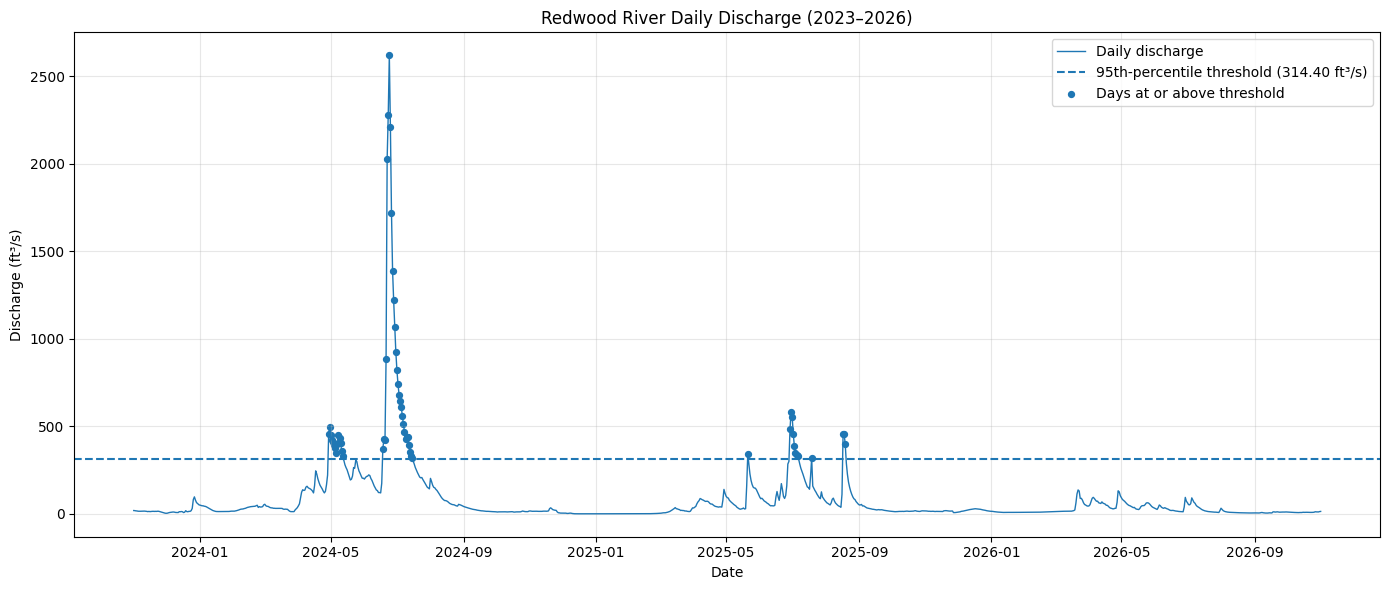

In [31]:
##7.2 Chart 1: Daily Discharge and High Flow Threshold
plt.figure(figsize=(14, 6))

plt.plot(
    river_weather["time"],
    river_weather["value"],
    label="Daily discharge",
    linewidth=1
)

plt.axhline(
    flood_threshold,
    linestyle="--",
    label=f"95th-percentile threshold ({flood_threshold:.2f} ft³/s)"
)

high_flow = river_weather[river_weather["flood_flag"]]

plt.scatter(
    high_flow["time"],
    high_flow["value"],
    label="Days at or above threshold",
    s=18
)

plt.title("Redwood River Daily Discharge (2023–2026)")
plt.xlabel("Date")
plt.ylabel("Discharge (ft³/s)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

os.makedirs("charts", exist_ok=True)
plt.savefig("charts/daily_discharge.png", dpi=300)
plt.show()

The high flow events generally occured between May and September of 2024 and 2025. 2024 had the highest discharge event at over 2500 cubic feet per second.

The chart below shows the river discharge and rainfall during a 21 day period around the wettest day in the weather datasset. Rainfall is displayed as bars and river discharged is displayed as a line. The purpose of this chart is to compare the two to determine if river discharged increased after signifcant rainfall, and how long the response appeared to take.

Selected wettest day: 2024-08-05
Storm period: 2024-07-26 to 2024-08-15


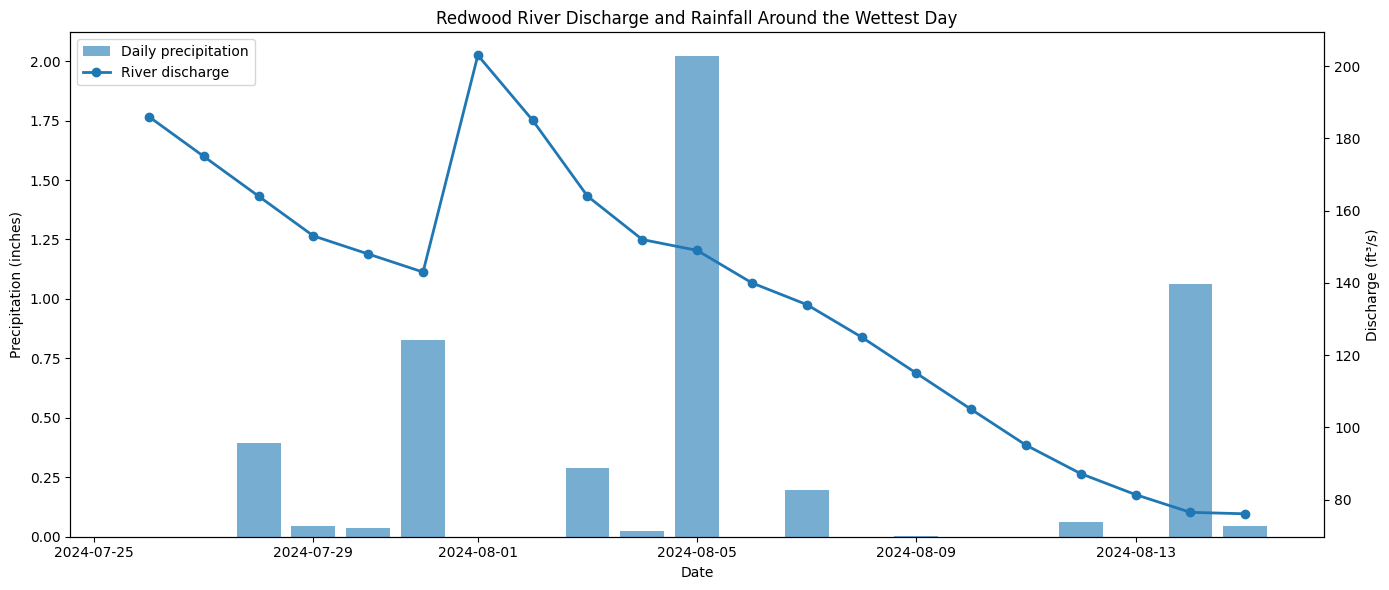

In [32]:
##Step 7.3 Chart 2: Rainfall and Discharge During Storm Period
# Select the wettest day with at least 10 days of data on either side
weather_candidates = weather_df.dropna(subset=["precipitation_in"]).copy()

start_allowed = weather_candidates["time"].min() + pd.Timedelta(days=10)
end_allowed = weather_candidates["time"].max() - pd.Timedelta(days=10)

weather_candidates = weather_candidates[
    (weather_candidates["time"] >= start_allowed) &
    (weather_candidates["time"] <= end_allowed)
]

storm_center = weather_candidates.loc[
    weather_candidates["precipitation_in"].idxmax(), "time"
]

storm_start = storm_center - pd.Timedelta(days=10)
storm_end = storm_center + pd.Timedelta(days=10)

storm_data = river_weather[
    (river_weather["time"] >= storm_start) &
    (river_weather["time"] <= storm_end)
].copy()

print("Selected wettest day:", storm_center.date())
print("Storm period:", storm_start.date(), "to", storm_end.date())

# Plot rainfall and discharge with separate vertical axes
fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.bar(
    storm_data["time"],
    storm_data["precipitation_in"],
    width=0.8,
    alpha=0.6,
    label="Daily precipitation"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Precipitation (inches)")

ax2 = ax1.twinx()

ax2.plot(
    storm_data["time"],
    storm_data["value"],
    marker="o",
    linewidth=2,
    label="River discharge"
)

ax2.set_ylabel("Discharge (ft³/s)")

plt.title("Redwood River Discharge and Rainfall Around the Wettest Day")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

fig.tight_layout()
plt.savefig("charts/storm_event.png", dpi=300)
plt.show()

Discharge did not seem to increase after significant rainfall on most days. The only instance where river discharge did increase after major rainfall was on 2024-08-01. On 2024-08-05 where there was the highest rainfall, river discharge actually dropped substantially the following day.

The scatter plot below compares total rainfall over three days with the change in river discharge from the previous day. Each point is one daily observation. This chart helps to find if there is a correlation between heavier recent rainfall and river discharge.

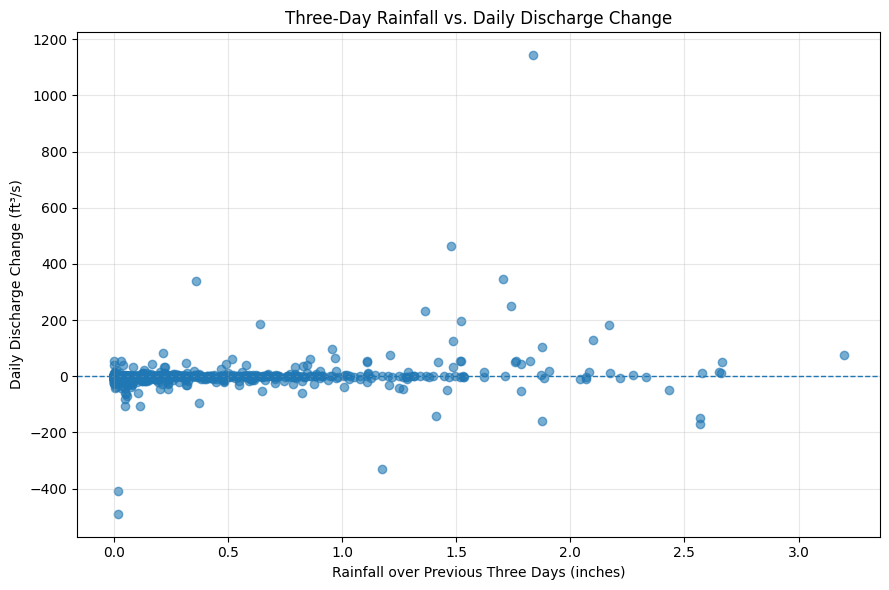

Number of observations: 1091
Correlation: 0.182


In [33]:
##Step 7.4 Chart 3: Three Day Rainfall VS Discharge Change
scatter_data = river_weather.dropna(
    subset=["rainfall_3day_in", "discharge_change"]
).copy()

plt.figure(figsize=(9, 6))

plt.scatter(
    scatter_data["rainfall_3day_in"],
    scatter_data["discharge_change"],
    alpha=0.6
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Three-Day Rainfall vs. Daily Discharge Change")
plt.xlabel("Rainfall over Previous Three Days (inches)")
plt.ylabel("Daily Discharge Change (ft³/s)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("charts/rainfall_vs_discharge_change.png", dpi=300)
plt.show()

correlation = scatter_data[
    ["rainfall_3day_in", "discharge_change"]
].corr().iloc[0, 1]

print("Number of observations:", len(scatter_data))
print("Correlation:", round(correlation, 3))

There appears to be very little correlation between heavy rainfall and river discharge according to the scatter plot.

I use the cell below to summarize my main results before I write my final conclusions. It takes the relevant information from the previous steps and prints them out.

In [34]:
##Gathering Final Results
# High-flow days per year
river_weather["year"] = river_weather["time"].dt.year

flood_days_by_year = (
    river_weather.groupby("year")["flood_flag"]
    .sum()
    .reset_index(name="flagged_days")
)

print("95th-percentile discharge threshold:",
      round(flood_threshold, 2), "ft³/s")

print("\nHigh-flow days by year:")
display(flood_days_by_year)

# Find the longest consecutive run of flagged calendar days
flagged_dates = (
    river_weather.loc[river_weather["flood_flag"], "time"]
    .sort_values()
    .tolist()
)

longest_run = 0
current_run = 0
previous_date = None

for date in flagged_dates:
    if previous_date is not None and (date - previous_date).days == 1:
        current_run += 1
    else:
        current_run = 1

    longest_run = max(longest_run, current_run)
    previous_date = date

print("\nLongest consecutive high-flow run:", longest_run, "days")

# Rainfall and discharge correlation
scatter_data = river_weather.dropna(
    subset=["rainfall_3day_in", "discharge_change"]
)

correlation = scatter_data[
    ["rainfall_3day_in", "discharge_change"]
].corr().iloc[0, 1]

print("Rainfall/discharge-change correlation:",
      round(correlation, 3))

95th-percentile discharge threshold: 314.4 ft³/s

High-flow days by year:


,year,flagged_days
0,2023,0
1,2024,42
2,2025,13
3,2026,0



Longest consecutive high-flow run: 28 days
Rainfall/discharge-change correlation: 0.182


My main results were summarized above.

## Conclusions

This project investigated the relationship between rainfall and river discharge in the Redwood River near Marshall, Minnesota, from November 2023 through November 2026.

The analysis found that river discharge varied considerably throughout the study period. Using the 95th percentile of daily discharge, a high-flow threshold of approximately 314.4 ft³/s was established. A total of 55 days exceeded this threshold, including 42 days in 2024 and 13 days in 2025. The longest consecutive period of high flow lasted 28 days.

Heavy rainfall appeared to be associated with delayed changes in river discharge. The analysis identified 55 heavy-rain observations using a rainfall threshold of approximately 0.584 inches. The median time between a heavy-rain day and the highest discharge observed during the following seven days was approximately 2 days.

The storm-event analysis examined July 26 through August 15, 2024. The wettest day occurred on August 5, with approximately 2.02 inches of precipitation. However, river discharge had already reached its highest plotted value of approximately 203 ft³/s on August 1 and continued declining afterward. This demonstrates that the wettest individual day did not necessarily correspond to the highest river discharge.

The relationship between three-day rainfall and daily discharge change was relatively weak, with a correlation of 0.182. Overall, the results suggest that rainfall may influence river discharge, but the relationship is not consistent across individual events. Other factors, including snowmelt, soil conditions, and rainfall throughout the watershed, may also contribute to changes in river flow. The analysis identifies patterns and associations but does not establish a causal relationship.

## Limitations

Several limitations should be considered when interpreting the results:

1. **Limited geographic coverage:** The weather data was obtained using coordinates near the USGS river gauge. These observations may not represent precipitation conditions throughout the entire Redwood River watershed.

2. **Limited sample size:** The analysis covers approximately three years of daily observations. A longer period would provide more information about seasonal patterns, unusual rainfall events, and high-flow conditions.

3. **Statistical high-flow threshold:** The 95th-percentile discharge threshold of 314.4 ft³/s is a statistical measure rather than an official National Weather Service flood stage. Days exceeding this threshold should not automatically be interpreted as actual flood events.

4. **Other factors affecting river discharge:** River discharge is influenced by more than rainfall. Snowmelt, soil moisture, groundwater conditions, upstream runoff, land use, and watershed characteristics may also affect river flow.

5. **USGS measurement uncertainty:** Some discharge observations were provisional or included estimated and force-interpolated qualifiers. These measurements may be revised or have greater uncertainty than approved observations.

6. **Simplified rainfall-response analysis:** The rainfall-to-peak calculation examines the highest discharge within seven days after each heavy-rain observation. Multiple heavy-rain observations may belong to the same storm, and the resulting peak may be influenced by other weather events.

7. **Association does not establish causation:** The weak positive correlation of 0.182 does not prove that rainfall caused changes in river discharge. The relationship may also be affected by other environmental conditions and the timing of rainfall.

8. **Incomplete calendar years:** The available data for 2023 and 2026 does not cover complete calendar years. Therefore, their annual high-flow counts cannot be directly compared with the full years of 2024 and 2025.

## Data Sources and Attribution

This project used two public data sources:

**1. United States Geological Survey (USGS) Water Data API**

- Website: https://waterdata.usgs.gov/
- API documentation: https://api.waterdata.usgs.gov/
- Used to retrieve daily mean discharge measurements for the Redwood River near Marshall, Minnesota (USGS-05315000).
- The dataset included daily discharge measurements in cubic feet per second (ft³/s).

**2. Open-Meteo Historical Weather API**

- Website: https://open-meteo.com/en/docs/historical-weather-api
- Used to retrieve historical daily precipitation, snowfall, and mean temperature observations near the selected USGS gauge.
- Weather observations were combined with the river discharge measurements using their corresponding dates.

**Tools and libraries used:**

- Python
- Pandas for data manipulation, cleaning, and combining datasets
- NumPy for numerical calculations
- Matplotlib for data visualization
- SQLite for database storage and SQL queries
- Requests for API communication
- JSON for handling raw API responses

The data was retrieved from publicly accessible sources and processed for educational and analytical purposes. The original API responses were preserved in the `data/raw/` directory, while the cleaned and combined dataset and SQLite database were saved in `data/clean/`.

### AI Use Note

I used ChatGPT to help understand the assignment, troubleshoot Python code, and organize parts of the data analysis. I ran the code in Google Colab and used the results from my own datasets to interpret the findings.